<a href="https://colab.research.google.com/github/reedx8/IdentifyFacesLFW/blob/main/IdentifyFaces.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import pandas as pd
from sklearn.datasets import fetch_lfw_people # Labeled Faces in the Wild (LFW) dataset from scikit-learn

# Setting the minimum number of faces per person to 100, which means that five sets of faces corresponding to five famous people will be imported:
faces = fetch_lfw_people(min_faces_per_person=100, slice_=None)
faces.images = faces.images[:, 35:97, 39:86]
faces.data = faces.images.reshape(faces.images.shape[0], faces.images.shape[1] *
                                  faces.images.shape[2])
image_count = faces.images.shape[0]
image_height = faces.images.shape[1] # 62
image_width = faces.images.shape[2] # 47 (see dataset docs for more)
class_count = len(faces.target_names) # = number of output neurons (len = 5)

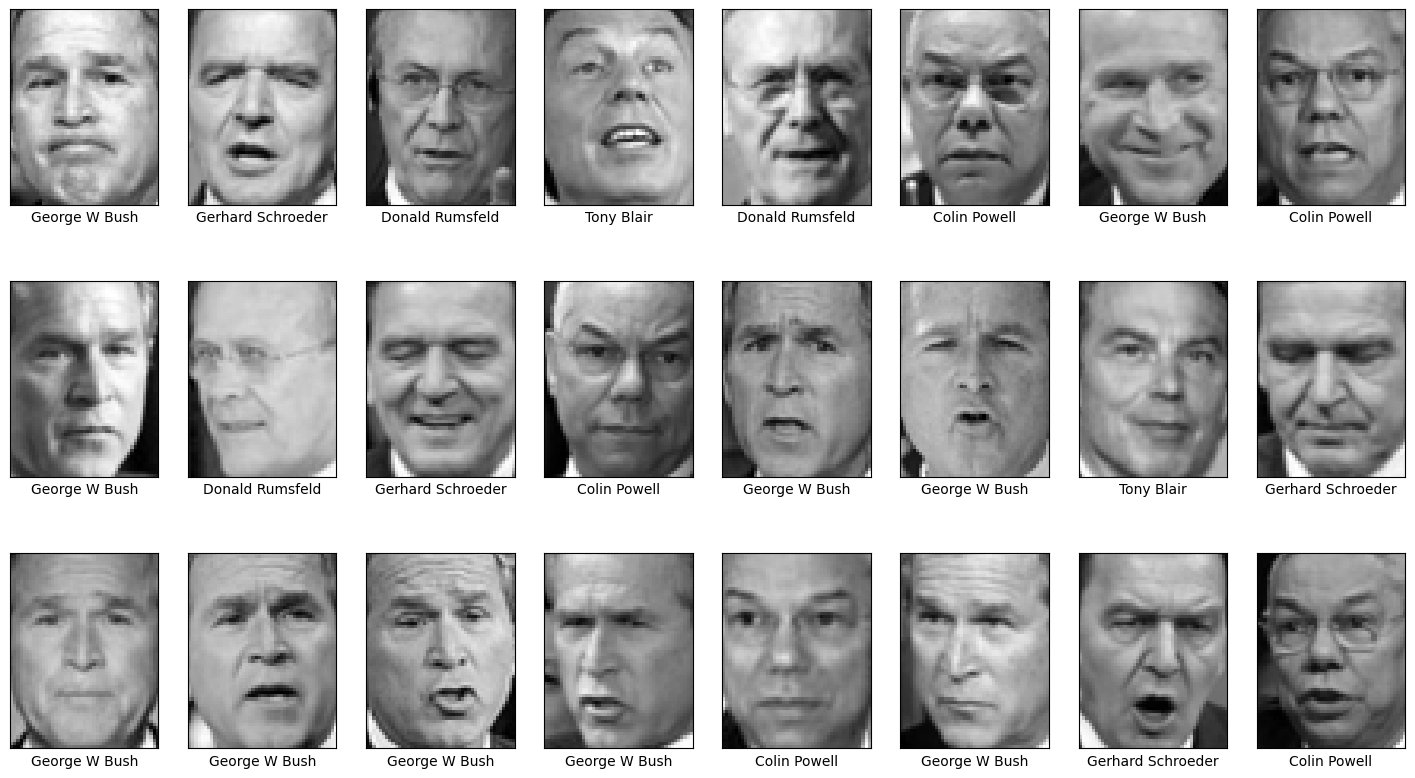

In [12]:
# (Optional) Show the first 24 images in the dataset and the people to whom the faces belong:

%matplotlib inline
import matplotlib.pyplot as plt

fig, ax = plt.subplots(3, 8, figsize=(18, 10))
for i, axi in enumerate(ax.flat):
    axi.imshow(faces.images[i], cmap='gist_gray')
    axi.set(xticks=[], yticks=[], xlabel=faces.target_names[faces.target[i]])

<Axes: >

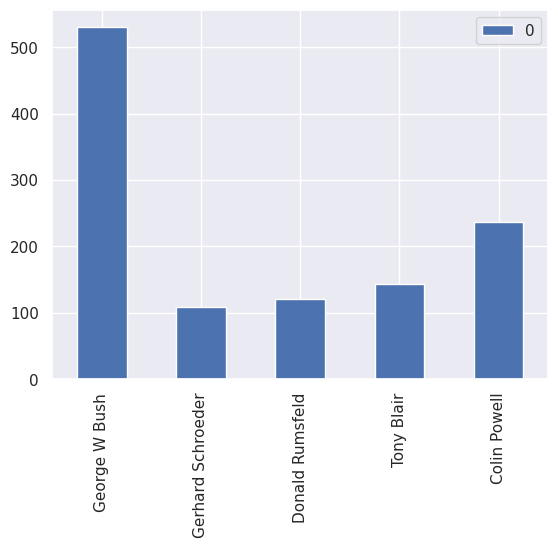

In [13]:
# Check the balance in the dataset by generating a histogram showing how many facial images were imported for each person (about 1,100 total images, skewed towards geroge bush):

from collections import Counter
import seaborn as sns
sns.set()

counts = Counter(faces.target)
names = {}

for key in counts.keys():
    names[faces.target_names[key]] = counts[key]

df = pd.DataFrame.from_dict(names, orient='index')
df.plot(kind='bar')

In [14]:
# To create a balanced dataset, use the following code to reduce the dataset to 100 images of each person:
import numpy as np

mask = np.zeros(faces.target.shape, dtype=bool)

for target in np.unique(faces.target):
    mask[np.where(faces.target == target)[0][:100]] = 1

# x_faces contains 500 facial images, and y_faces contains the labels that go with them: 0 for Colin Powell, 1 for Donald Rumsfeld, and so on.
x_faces = faces.data[mask]
y_faces = faces.target[mask]
x_faces.shape

(500, 2914)

In [15]:
# create train-test split, set aside 20% of the data for testing,
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x_faces, y_faces, train_size=0.8, stratify=y_faces, random_state=0)

In [62]:
# Create a neural network containing 1-3 hidden layers to capture more complex patterns. Use sparse_categorical_crossentropy as the loss function and softmax as the activation function in the output layer:

from tensorflow.keras.layers import Dense
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dropout

model = Sequential()

# First hidden layer (receives the raw input shape of 2914 pixels) -- In Keras's Sequential API, we often don't write a separate line for the raw input. Instead, we define the first physical layer of neurons (the first hidden layer) and pass the input_shape parameter directly into it. This tells Keras, "Create a hidden layer with 512 neurons, and expect an input layer of size 2,914 right before it. This means input layer is a flattened 2,914 vector.
model.add(Dense(512, activation='relu', input_shape=(image_width * image_height,))) # passing a 1 elem. tuple to input_shape, tf trailing comma
model.add(Dropout(0.26))

# Second hidden layer
# model.add(Dense(256, activation='relu'))
# model.add(Dropout(0.20))

# Third hidden layer
# model.add(Dense(128, activation='relu'))
# model.add(Dropout(0.2))

# Output layer
model.add(Dense(class_count, activation='softmax')) # class_count = # of output neurons = 5!

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_26 (Dense)                │ (None, 1024)           │     2,984,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 5)              │         5,125 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,990,085 (11.41 MB)

 Trainable params: 2,990,085 (11.41 MB)

 Non-trainable params: 0 (0.00 B)

In [63]:
# Train the NN
hist = model.fit(x_train, y_train, validation_data=(x_test, y_test),
                 epochs=100, batch_size=20)

Epoch 1/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 66ms/step - accuracy: 0.1975 - loss: 3.6317 - val_accuracy: 0.2000 - val_loss: 2.4780
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - accuracy: 0.2925 - loss: 1.9042 - val_accuracy: 0.3800 - val_loss: 1.4199
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.3625 - loss: 1.5279 - val_accuracy: 0.4100 - val_loss: 1.4328
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.3925 - loss: 1.4281 - val_accuracy: 0.5200 - val_loss: 1.3448
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.4250 - loss: 1.3817 - val_accuracy: 0.4800 - val_loss: 1.2887
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.5050 - loss: 1.2408 - val_accuracy: 0.6300 - val_loss: 1.2300
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.4625 - loss: 1.3373 - val_accuracy: 0.3400 - val_loss: 1.5230
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.4500 - loss: 1.3184 - val_accuracy: 0.

[]

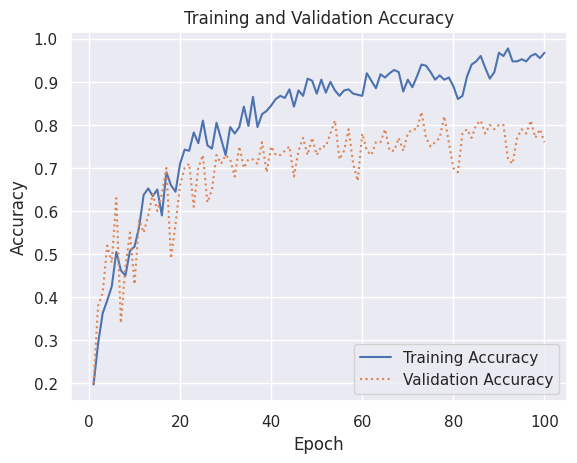

In [64]:
# Plot the training / validation accuracy and loss

acc = hist.history['accuracy']
val_acc = hist.history['val_accuracy']
epochs = range(1, len(acc) + 1)

plt.plot(epochs, acc, '-', label='Training Accuracy')
plt.plot(epochs, val_acc, ':', label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.plot()

# loss = hist.history['loss']
# val_loss = hist.history['val_loss']
# epochs = range(1, len(loss) + 1)

# plt.plot(epochs, loss, '-', label='Training Loss')
# plt.plot(epochs, val_loss, ':', label='Validation Loss')
# plt.title('Training and Validation Loss')
# plt.xlabel('Epoch')
# plt.ylabel('Loss')
# plt.legend(loc='upper right')
# plt.plot()

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step


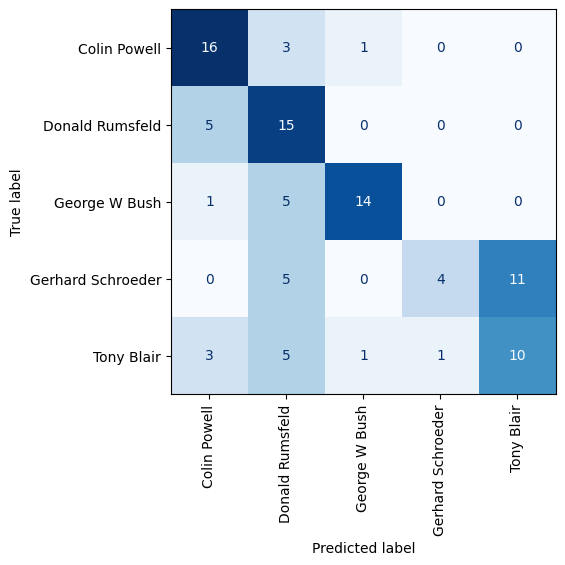

In [ ]:
# visualize confusion matrix to view how NN performs on test data (20 samples per person, its read row-wise)
from sklearn.metrics import ConfusionMatrixDisplay as cmd

sns.reset_orig()
y_pred = model.predict(x_test)
fig, ax = plt.subplots(figsize=(5, 5))
ax.grid(False)

cmd.from_predictions(y_test, y_pred.argmax(axis=1),
                     display_labels=faces.target_names, colorbar=False,
                     cmap='Blues', xticks_rotation='vertical', ax=ax)